## Data Science Practical: Exploratory Analysis of the Titanic Dataset

**Name:** Tanishka Bhalekar
**Date:** 4 October 2026
**Tools:** Python, Jupyter Notebook, NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn

## Objective
To set up a data science environment and practice data loading, cleaning,
transformation, visualization and basic statistical analysis on the Titanic
passenger dataset, and to document the observations and insights.

## Section 1: Environment Setup

1. Environment Setup
Python and Jupyter Notebook were already installed. The libraries NumPy, Pandas,
Matplotlib, Seaborn and Scikit-learn were imported and their versions checked
below to confirm the environment works.

In [1]:
import sys, numpy as np, pandas as pd, matplotlib, seaborn as sns, sklearn
print(sys.version)
for lib in [np, pd, matplotlib, sns, sklearn]:
    print(lib.__name__, lib.__version__)

3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
numpy 2.4.5
pandas 3.0.3
matplotlib 3.11.0
seaborn 0.13.2
sklearn 1.9.0


In [2]:
%pip install numpy pandas matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


**Observation:** All libraries imported without errors, so the environment is ready.

## Section 2: Data Loading

2. Data Loading and Overview
The Titanic dataset (from the Seaborn data repository) was saved as a CSV and
loaded with Pandas. It contains passenger details such as age, sex, class, fare
and whether the passenger survived.

In [1]:
import seaborn as sns
import os

df = sns.load_dataset("titanic")
os.makedirs("data", exist_ok=True)
df.to_csv("data/titanic.csv", index=False)
print(df.shape)

(891, 15)


**Observation:** The dataset has 891 rows and 15 columns. Age, deck, embarked and
embark_town contain missing values. Deck has the most missing data (about 77%).

## Section 3: Pandas and NumPy Operations

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [3]:
print(df.shape)
df.info()
df.describe(include="all")
df.isnull().sum()

(891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

## SELECTION

In [4]:
df["age"]                          # one column
df[["sex", "age", "fare"]]         # multiple columns
df.loc[0:5, ["sex", "age"]]        # label-based
df.iloc[0:5, 0:4]                  # position-based

,survived,pclass,sex,age
0,0,3,male,22.0
1,1,1,female,38.0
2,1,3,female,26.0
3,1,1,female,35.0
4,0,3,male,35.0


## FILTERING

In [5]:
df[df["age"] > 60]
df[(df["sex"] == "female") & (df["survived"] == 1)]
df[df["class"].isin(["First", "Second"])]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False
11,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
880,1,2,female,25.0,0,1,26.0000,S,Second,woman,False,NaN,Southampton,yes,False
883,0,2,male,28.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True


## SORTING

In [6]:
df.sort_values("fare", ascending=False).head(10)
df.sort_values(["pclass", "age"], ascending=[True, False]).head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
630,1,1,male,80.0,0,0,30.0000,S,First,man,True,A,Southampton,yes,True
96,0,1,male,71.0,0,0,34.6542,C,First,man,True,A,Cherbourg,no,True
493,0,1,male,71.0,0,0,49.5042,C,First,man,True,NaN,Cherbourg,no,True
745,0,1,male,70.0,1,1,71.0000,S,First,man,True,B,Southampton,no,False
54,0,1,male,65.0,0,1,61.9792,C,First,man,True,B,Cherbourg,no,False


## GROUPING

In [7]:
df.groupby("sex")["survived"].mean()
df.groupby("pclass").agg(avg_fare=("fare", "mean"),
                         max_age=("age", "max"),
                         passengers=("survived", "count"))
pd.pivot_table(df, values="survived", index="sex", columns="pclass", aggfunc="mean")

pclass,1,2,3
sex,,,
female,0.968085,0.921053,0.500000
male,0.368852,0.157407,0.135447


## MERGING

In [8]:
class_info = pd.DataFrame({
    "pclass": [1, 2, 3],
    "deck_level": ["Upper", "Middle", "Lower"]
})
merged = df.merge(class_info, on="pclass", how="left")
merged[["pclass", "deck_level"]].drop_duplicates()

,pclass,deck_level
0,3,Lower
1,1,Upper
9,2,Middle


## TRANSFORMATION

In [9]:
df["family_size"] = df["sibsp"] + df["parch"] + 1
df["fare_category"] = pd.cut(df["fare"], bins=[-1, 10, 50, 600],
                             labels=["Low", "Medium", "High"])
df["name_len"] = df["sex"].apply(len)   # simple apply example
df["sex"].map({"male": 0, "female": 1}).head()

0    0
1    1
2    1
3    1
4    0
Name: sex, dtype: int64

## NumPY OPERATIONS

In [10]:
arr = df["fare"].dropna().to_numpy()
print(np.mean(arr), np.median(arr), np.std(arr))
print(np.percentile(arr, [25, 50, 75]))
print(np.where(arr > 100, "Expensive", "Normal")[:10])

a = np.arange(1, 13).reshape(3, 4)
print(a, a.T, a.sum(axis=0), a * 2, sep="\n")
rand = np.random.normal(50, 10, 1000)   # simulated data

32.204207968574636 14.4542 49.6655344447741
[ 7.9104 14.4542 31.    ]
['Normal' 'Normal' 'Normal' 'Normal' 'Normal' 'Normal' 'Normal' 'Normal'
 'Normal' 'Normal']
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
[[ 1  5  9]
 [ 2  6 10]
 [ 3  7 11]
 [ 4  8 12]]
[15 18 21 24]
[[ 2  4  6  8]
 [10 12 14 16]
 [18 20 22 24]]


## Section 4 : Data Cleaning

In [13]:
clean = df.copy()

**1. Missing Values**

In [14]:
clean.isnull().sum().sort_values(ascending=False)
(clean.isnull().mean() * 100).round(1)       # % missing

survived          0.0
pclass            0.0
sex               0.0
age              19.9
sibsp             0.0
parch             0.0
fare              0.0
embarked          0.2
class             0.0
who               0.0
adult_male        0.0
deck             77.2
embark_town       0.2
alive             0.0
alone             0.0
family_size       0.0
fare_category     0.0
name_len          0.0
dtype: float64

In [15]:
clean["age"] = clean["age"].fillna(clean["age"].median())              # numeric: median
clean["embarked"] = clean["embarked"].fillna(clean["embarked"].mode()[0])  # categorical: mode
clean = clean.drop(columns=["deck"])          # ~77% missing, so drop
clean = clean.dropna(subset=["embark_town"])  # few rows, so drop

**2. Duplicates**

In [16]:
print(clean.duplicated().sum())
clean = clean.drop_duplicates()

116


**3. Inconsistent data**

In [17]:
clean["sex"] = clean["sex"].str.strip().str.lower()
clean["embark_town"] = clean["embark_town"].str.title()
clean["who"].value_counts()   # check for spelling variants

who
man      443
woman    248
child     82
Name: count, dtype: int64

**4. Incorrect data types**

In [18]:
clean["survived"] = clean["survived"].astype("category")
clean["pclass"] = clean["pclass"].astype("category")
clean["age"] = clean["age"].astype(int)
clean.dtypes

survived         category
pclass           category
sex                   str
age                 int64
sibsp               int64
parch               int64
fare              float64
embarked              str
class            category
who                   str
adult_male           bool
embark_town           str
alive                 str
alone                bool
family_size         int64
fare_category    category
name_len            int64
dtype: object

**5. Outliers**

In [19]:
Q1, Q3 = clean["fare"].quantile([0.25, 0.75])
IQR = Q3 - Q1
outliers = clean[(clean["fare"] < Q1 - 1.5*IQR) | (clean["fare"] > Q3 + 1.5*IQR)]
print(len(outliers), "outliers in fare")

100 outliers in fare


In [20]:
df.shape

(891, 18)

clean.shape

## Section 5: Visualizations

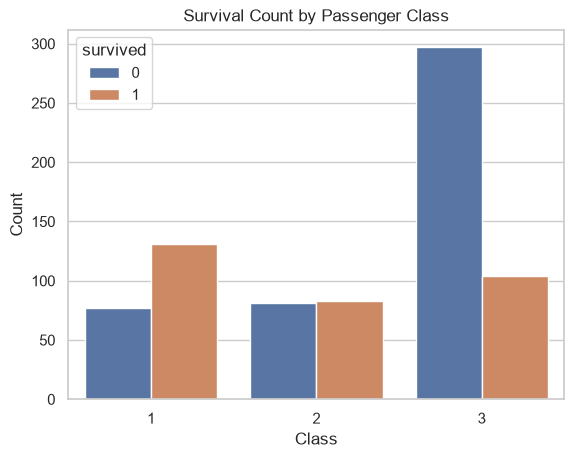

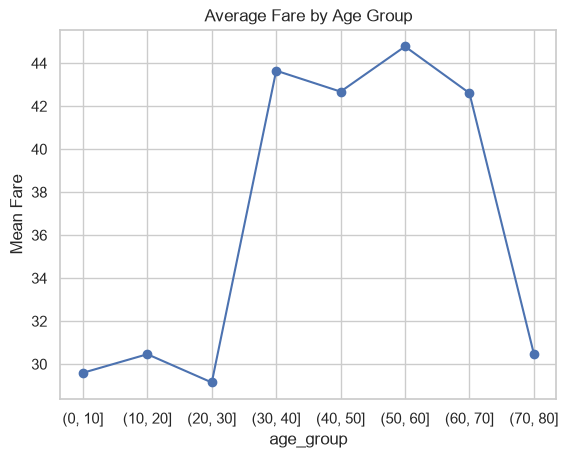

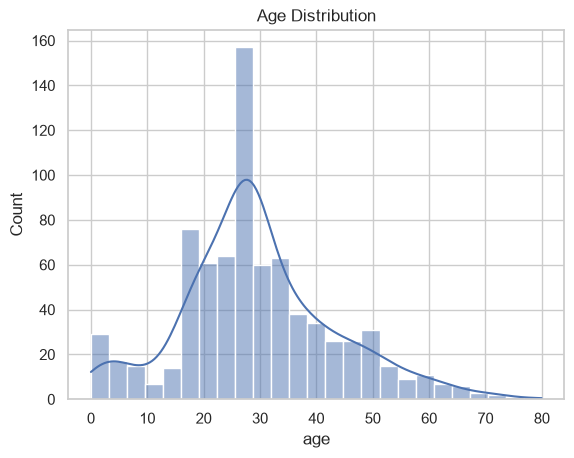

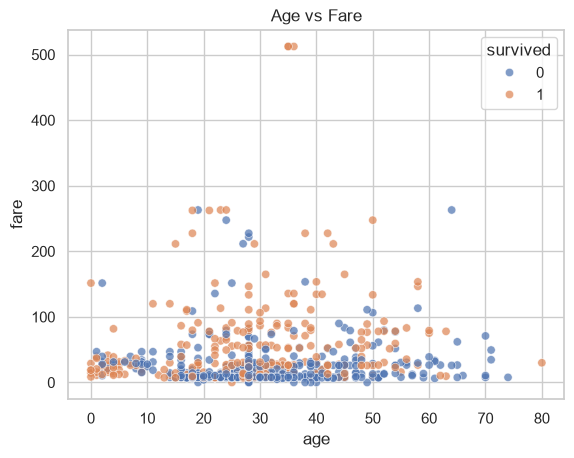

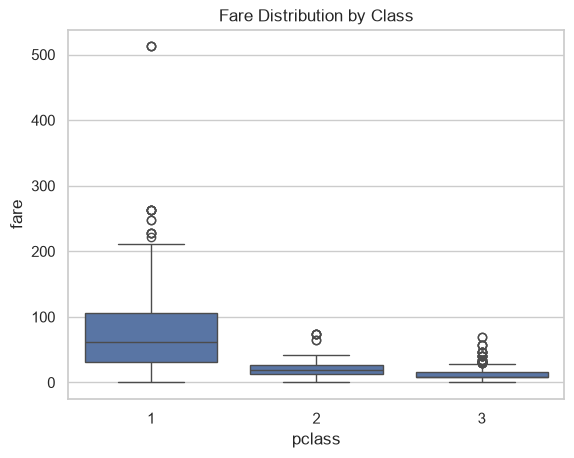

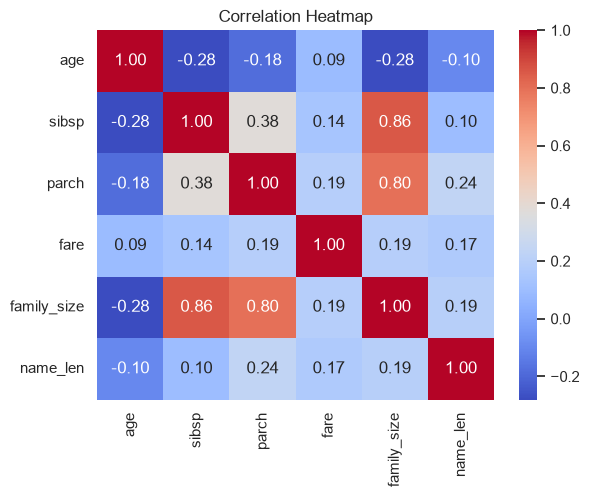

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


<Axes: xlabel='family_size', ylabel='Density'>

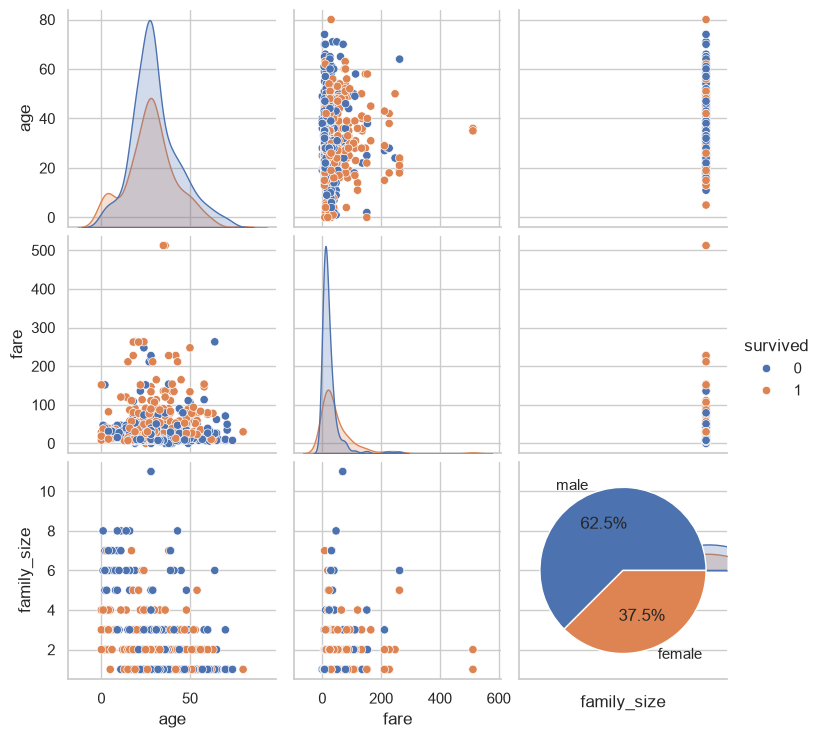

In [22]:
# Bar chart: survival by class
sns.countplot(data=clean, x="pclass", hue="survived")
plt.title("Survival Count by Passenger Class")
plt.xlabel("Class"); plt.ylabel("Count"); plt.show()

# Line chart: average fare by age group
clean["age_group"] = pd.cut(clean["age"], bins=range(0, 90, 10))
clean.groupby("age_group")["fare"].mean().plot(kind="line", marker="o")
plt.title("Average Fare by Age Group"); plt.ylabel("Mean Fare"); plt.show()

# Histogram
sns.histplot(clean["age"], bins=25, kde=True)
plt.title("Age Distribution"); plt.show()

# Scatter plot
sns.scatterplot(data=clean, x="age", y="fare", hue="survived", alpha=0.7)
plt.title("Age vs Fare"); plt.show()

# Box plot
sns.boxplot(data=clean, x="pclass", y="fare")
plt.title("Fare Distribution by Class"); plt.show()

# Heatmap (correlation)
sns.heatmap(clean.select_dtypes("number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap"); plt.show()

# Extras: pairplot, violin, pie
sns.pairplot(clean[["age", "fare", "family_size", "survived"]].astype({"survived": int}), hue="survived")
clean["sex"].value_counts().plot(kind="pie", autopct="%1.1f%%")

## Section 6: Descriptive statistics and analysis

In [23]:
clean[["age", "fare"]].describe()
clean["age"].agg(["mean", "median", "std", "var", "min", "max", "skew", "kurt"])
clean["age"].mode()
clean["fare"].quantile([.25, .5, .75])

0.25     8.05
0.50    15.90
0.75    33.50
Name: fare, dtype: float64

**Relationships and correlations**

In [24]:
num = clean.select_dtypes("number")
num.corr()
clean["fare"].corr(clean["age"])

np.float64(0.08984007074582917)

**Group comparisons and patterns**

In [25]:
clean.groupby("sex")["survived"].apply(lambda s: (s == 1).mean())
pd.crosstab(clean["pclass"], clean["survived"], normalize="index")

survived,0,1
pclass,,
1,0.370192,0.629808
2,0.493902,0.506098
3,0.740648,0.259352


## Section 7 : Summary

**PART 1 :**

**Objective 1: Environment setup.**
Python and Jupyter Notebook were already installed. NumPy, Pandas, Matplotlib,
Seaborn and Scikit-learn were imported and their versions verified, confirming
the environment was ready for data science work.

**Objective 2: Working with Pandas and NumPy.**
The Titanic dataset ([891] rows, [15] columns) was loaded from a CSV file. Data
was selected, filtered, sorted, grouped, aggregated, merged and transformed
using Pandas. NumPy was used for descriptive calculations, percentiles, array
reshaping and conditional operations.

**Objective 3: Data cleaning.**
Missing values were handled using the median for age, the mode for embarked, and
by dropping the deck column, which was about [77]% empty. Duplicates were
removed, text values were standardized, data types were corrected, and outliers
in fare were checked using the IQR method. The dataset went from [891] rows with
[X] missing values to [X] rows with no missing values.

**Objective 4: Data visualization.**
Bar charts, a line chart, a histogram, a scatter plot, a box plot and a
correlation heatmap were created with Matplotlib and Seaborn. Each chart has a
title, labelled axes and a written interpretation.

**Objective 5: Basic data analysis.**
Descriptive statistics (mean, median, mode, standard deviation, skewness and
quartiles) were calculated. Distributions, correlations and group comparisons
were examined to identify patterns in survival, age and fare.

**Objective 6: Documentation.**
All code, outputs, charts and observations were documented in this structured
notebook, which runs from top to bottom using Restart & Run All.

---
**PART 2 :**
 **Key Insights**
- **Sex was strongly linked to survival:** about [74]% of women survived compared
  with about [19]% of men.
- **Class mattered:** survival rate fell from about [63]% in first class to about
  [47]% in second class and [24]% in third class.
- **Fare is right-skewed:** the mean fare ([32.2]) is well above the median
  ([14.5]), because a few tickets cost over [500].
- **Fare is negatively correlated with class** (r = [-0.55]), so higher classes
  paid more.
- **Age was concentrated between 20 and 40:** the median age was about [28], and
  [177] missing ages (about [20]%) were filled with the median.
- **Family size showed a pattern:** passengers travelling alone had a survival
  rate of about [30]%, compared with [X]% for small families.
  
**PART 3 :**
**Limitations**
- **Imputation affects results:** filling age with the median reduces natural
  variation and may slightly bias the age statistics.
- **Dropping the deck column** removed information that could have shown
  location-based survival differences.
- **Correlation is not causation:** the relationships found do not prove that sex
  or class caused survival.
- **Outliers were kept:** extreme fares may influence the mean and the correlation
  values.
- **Limited scope:** the dataset covers a single event and 891 passengers, so
  findings may not generalize to other situations.
- **Analysis was descriptive only:** no predictive model or statistical test was
  used to confirm the patterns.

**PART 4 :**
**Conclusion**
This practical successfully covered the complete data analysis workflow: setting up the environment, manipulating data with Pandas and NumPy, cleaning data quality issues, creating visualizations, and calculating descriptive statistics. The analysis showed that passenger sex and class were the strongest factors associated with survival on the Titanic, while fare was heavily right-skewed.The workflow is documented and reproducible, and could be extended in future work with predictive modelling such as logistic regression using Scikit-learn.